In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocbessing import StandardScaler

In [4]:
X,y_true = make_blobs(n_samples=100,centers=3, cluster_std = 0.60,random_state=42)

In [5]:
X

array([[-7.38770342, -7.78901793],
       [ 5.12798917,  1.23465109],
       [-2.79088225,  9.33982215],
       [ 5.48155542,  1.13205905],
       [-6.66495477, -6.54363888],
       [ 4.04555704,  1.63339105],
       [-2.31043956,  9.5996132 ],
       [ 4.5080757 ,  2.18743723],
       [ 4.69812537,  2.55435668],
       [-3.19979377,  9.23970494],
       [-2.83582726,  9.08083968],
       [-6.74315123, -6.09582394],
       [-6.56646225, -6.70191879],
       [-3.17299861,  8.29656215],
       [-2.06611768,  9.1171071 ],
       [-7.52216269, -6.59062614],
       [-6.71361271, -6.38379964],
       [-2.5524037 ,  9.61640587],
       [-7.40994165, -6.78787453],
       [-6.59568462, -6.92380694],
       [-2.78724824,  8.73484828],
       [-6.92588822, -6.67541841],
       [-7.14753616, -6.36627032],
       [-2.29236026,  9.93710807],
       [-2.53069325,  9.95307232],
       [-2.78558089,  9.64855946],
       [ 3.79065639,  1.72078249],
       [-6.50422678, -7.39440413],
       [-7.46443619,

In [7]:
df = pd.DataFrame(X, columns=["Feature_1","Feature_2"])

In [8]:
df 

,Feature_1,Feature_2
0,-7.387703,-7.789018
1,5.127989,1.234651
2,-2.790882,9.339822
3,5.481555,1.132059
4,-6.664955,-6.543639
...,...,...
95,-2.915351,9.381292
96,-1.890598,9.573054
97,4.543107,2.215600
98,-6.229796,-6.247828


In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

ELBOW METHOD

In [11]:
inertia = []
K_range = range(1, 11)

In [12]:
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

In [13]:
inertia

[200.0,
 59.930275129666825,
 2.0331401136396368,
 1.7440678422876643,
 1.482640696254919,
 1.3907613511330106,
 1.1422705097654795,
 0.9740243472092618,
 0.9155190035597232,
 0.7641617436454584]

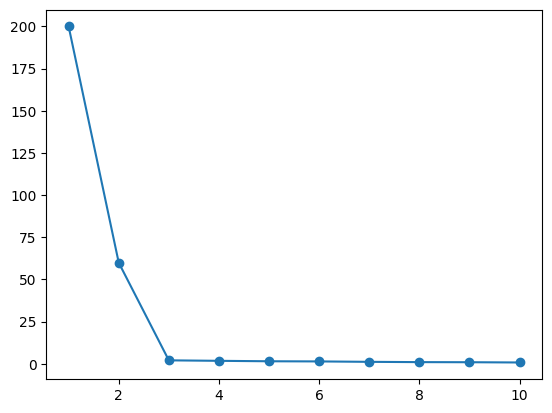

In [14]:
plt.plot(K_range,inertia,marker ="o")

In [15]:
kmeans_final = KMeans(n_clusters=3, random_state=42)

In [16]:
cluster_labels = kmeans_final.fit_predict(X_scaled)

In [17]:
df['cluster'] = cluster_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

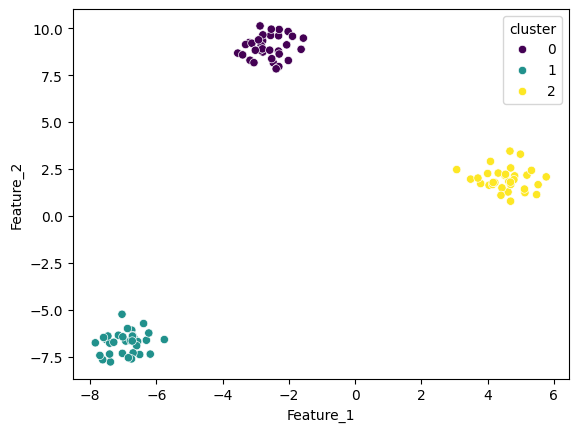

In [18]:
sns.scatterplot(
    x=df['Feature_1'],
    y=df['Feature_2'],
    hue=df['cluster'],
    palette='viridis'
)